# 05 · 相关性与市场波动：QuantumBridge × 夸父云

        面向会基础 Python、概率和量子门的读者。本笔记可从首格运行到末格，默认不访问网络、
        不读取密钥、不产生真机任务。目标是一个可核验的小规模端到端案例，不等于该金融行业全部能力。

        数据全部为明确给定的合成数据，不是投资建议，不用于真实交易或生产风险管理。
        步骤：原理 → 输入与经典参考 → 电路与中间结果 → 本地实际采样 → 云任务与结果 → 最终比较。

In [1]:
from pathlib import Path
import json, os, sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'quantumbridge').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Run this notebook from inside the QuantumBridge repository')
sys.path.insert(0, str(ROOT))
from quantumbridge.finance import build_finance_cases, run_local, FinanceCloudSession
from quantumbridge.finance.execution import circuit_artifact
from quantumbridge.finance.kernels import labels
from quantumbridge.devices import StatevectorDevice
import html
def pretty(value):
    print(json.dumps(value, ensure_ascii=False, indent=2))
def display_table(rows, fields):
    table = '<table><thead><tr>' + ''.join('<th>' + html.escape(f) + '</th>' for f in fields) + '</tr></thead><tbody>'
    for row in rows:
        table += '<tr>' + ''.join('<td>' + html.escape(str(row[f])) + '</td>' for f in fields) + '</tr>'
    display(HTML(table + '</tbody></table>'))
case = build_finance_cases()['correlation']
if os.environ.get('QB_FINANCE_REPLAY_HARDWARE') == '1':
    from quantumbridge.finance.acceptance import restore_submitted_circuits
    case = restore_submitted_circuits(case, ROOT / 'output' / 'finance-hardware' / 'session.json')
    print('Using EXACT originally submitted QASM; strict plan/receipt hashes retained.')
print('Case:', case.key, '| quantum circuits:', len(case.experiments))
print('Result labels use q0-first ordering. Cloud ordering is calibrated separately.')

Using EXACT originally submitted QASM; strict plan/receipt hashes retained.
Case: correlation | quantum circuits: 3
Result labels use q0-first ordering. Cloud ordering is calibrated separately.


## 1. 原理：带符号干涉相关性与历史波动率

对8天合成收益序列，先中心化并归一化：
$u=(a-\bar a)/\|a-\bar a\|$，$v=(b-\bar b)/\|b-\bar b\|$。
Pearson 相关系数为 $\rho=u^Tv$。制备4比特态
$|\Psi\rangle=(|0\rangle|u\rangle+|1\rangle|v\rangle)/\sqrt2$，
再对首比特做 H 门，测得 $P(0)=(1+\rho)/2$，因此 $\rho=2P(0)-1$。
这里保留实振幅的符号；普通 SWAP-test 得到 $|u^Tv|^2$，会丢失正负号，不能直接替代。

同时对3比特均匀时间索引做一次测量，将 counts 作为历史收益的重采样权重。
$\bar r=\sum_j\hat p_jr_j$，$\sigma_d=\sqrt{\sum_j\hat p_j(r_j-\bar r)^2}$，
假设独立同分布且每年252交易日，$\sigma_{ann}=\sqrt{252}\sigma_d$。
这是 ddof=0 的历史总体波动率，不是无偏样本估计，不是未来波动率预测。

实现步骤：生成合成收益 → 中心化/归一化 → 对正、负相关各制备一次干涉态 →
测量首比特 → 恢复相关系数与采样标准误差 → 测量时间索引 → 估计均值/波动率。
使用16个真实振幅的经典数据加载，不宣称大数据加速或已训练金融 AI 模型。

## 2. 输入模型与精确对照
先检查输入、量纲和约束，随后所有量子采样结果使用同一个模型比较。

In [2]:
pretty(case.inputs)

{
  "asset_a_returns": [
    0.01,
    -0.02,
    0.015,
    0.005,
    -0.01,
    0.025,
    -0.005,
    -0.015
  ],
  "asset_b_returns": [
    0.01,
    -0.013000000000000001,
    0.005999999999999999,
    0.005,
    -0.01,
    0.016,
    0.0,
    -0.011
  ],
  "asset_c_returns": [
    -0.004,
    0.015,
    -0.015,
    -0.002,
    0.004,
    -0.019000000000000003,
    0.007,
    0.01
  ],
  "data_source": "8 synthetic daily returns; no live data"
}


Classical Pearson matrix:
[[ 1.          0.96617392 -0.97266612]
 [ 0.96617392  1.         -0.87988017]
 [-0.97266612 -0.87988017  1.        ]]


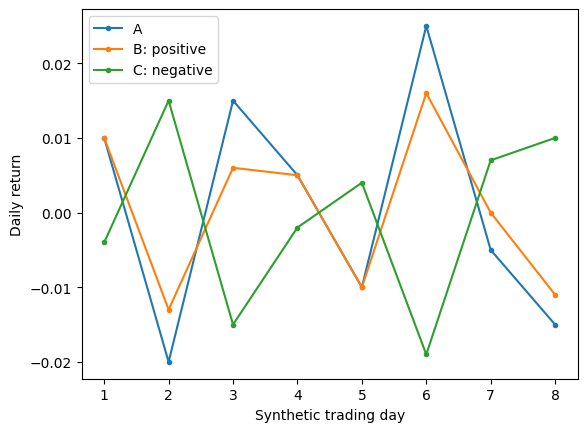

Centered normalized A: [0.22592821242329172, -0.49704206733124184, 0.3464232590490473, 0.10543316579753616, -0.2560519740797306, 0.5874133523005586, -0.13555692745397505, -0.37654702070548624]
{
  "positive_correlation": 0.9661739219933148,
  "negative_correlation": -0.9726661195352715,
  "daily_return_mean": 0.0006250000000000001,
  "daily_volatility": 0.01467086824288188,
  "annualized_volatility_252": 0.23289281332836362
}


In [3]:
returns = np.array([case.inputs['asset_a_returns'], case.inputs['asset_b_returns'],
                    case.inputs['asset_c_returns']])
print('Classical Pearson matrix:'); print(np.corrcoef(returns))
for name, series in zip(['A', 'B: positive', 'C: negative'], returns):
    plt.plot(range(1, 9), series, marker='.', label=name)
plt.xlabel('Synthetic trading day'); plt.ylabel('Daily return'); plt.legend(); plt.show()
print('Centered normalized A:', case.intermediate['normalized_asset_a'])
pretty(case.reference)

## 3. 中间效果：电路、门数、理想概率

        所有实际提交门限定为 H、RY、RX、RZ、CX。概率/带符号实振幅加载在本地生成门序列，
        不是在云上执行 Python/NumPy。下格展示将提交的完整 QASM、量子比特数、双比特门数以及
        本地理想概率。真实设备的编译映射和噪声可能改变深度与分布。

In [4]:
for name, circuit in case.experiments.items():
    artifact = circuit_artifact(circuit)
    print(name, '| qubits:', artifact['num_qubits'], '| gates:', artifact['gates'],
          '| two-qubit gates:', artifact['two_qubit_gates'], '| SHA256:', artifact['sha256'])
    print(artifact['openqasm'])
    print('Ideal probabilities:', StatevectorDevice().probabilities(circuit))

positive_correlation | qubits: 4 | gates: 50 | two-qubit gates: 34 | SHA256: dfbdce9bd41a8304caaf9ed22b756e643f356552a32b0f9ba80c724d44af0e46
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[4];
ry(1.5707963267948963) q[0];
ry(1.7396937540038238) q[1];
cx q[0],q[1];
ry(-0.026859513181998751) q[1];
cx q[0],q[1];
ry(1.052713990075457) q[2];
cx q[1],q[2];
ry(-0.050967351189937449) q[2];
cx q[1],q[2];
cx q[0],q[2];
ry(0.091179168652661291) q[2];
cx q[0],q[2];
cx q[0],q[2];
cx q[1],q[2];
ry(0.07831778700455061) q[2];
cx q[1],q[2];
cx q[0],q[2];
ry(-0.12222362598694581) q[3];
cx q[2],q[3];
ry(1.1460351387611547) q[3];
cx q[2],q[3];
cx q[1],q[3];
ry(-0.43157764899249385) q[3];
cx q[1],q[3];
cx q[1],q[3];
cx q[2],q[3];
ry(-2.683422216030197) q[3];
cx q[2],q[3];
cx q[1],q[3];
cx q[0],q[3];
ry(-0.26938588887112846) q[3];
cx q[0],q[3];
cx q[0],q[3];
cx q[2],q[3];
ry(0.083266416613659855) q[3];
cx q[2],q[3];
cx q[0],q[3];
cx q[0],q[3];
cx q[1],q[3];
ry(-0.025540832673732528) q[3];
cx q[1],q[3

## 4. 中间效果：1024 shots 本地实际采样
固定种子保证可重现。以下输出明确是本地模拟器，不是真机结果。

positive_correlation local_simulator | measured shots: 1024
Raw measured counts: {'0010': 79, '0101': 303, '0111': 175, '0001': 232, '0100': 103, '1010': 9, '0000': 91, '0011': 13, '1110': 7, '1000': 6, '1100': 3, '0110': 3}


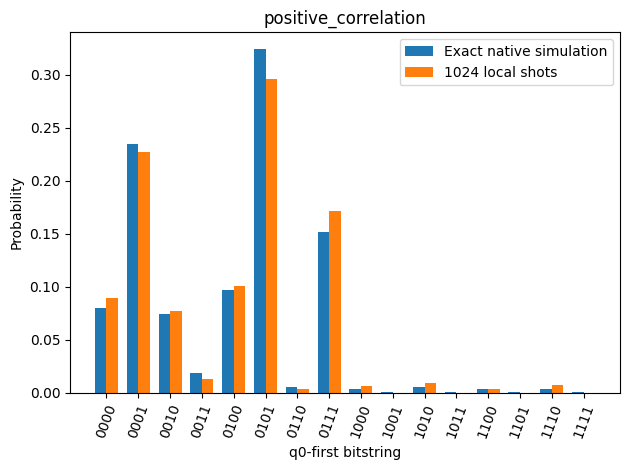

negative_correlation local_simulator | measured shots: 1024
Raw measured counts: {'1101': 364, '1100': 38, '1010': 167, '1000': 27, '1111': 135, '1001': 234, '1110': 30, '0100': 3, '1011': 12, '0000': 6, '0110': 6, '0010': 2}


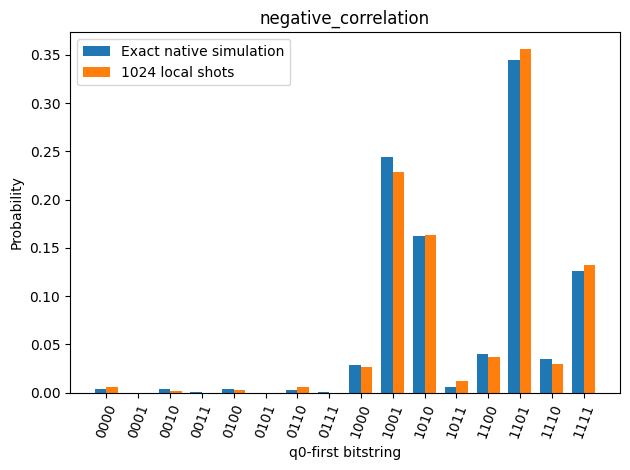

time_sampling local_simulator | measured shots: 1024
Raw measured counts: {'001': 142, '010': 120, '101': 115, '000': 123, '100': 121, '110': 132, '111': 127, '011': 144}


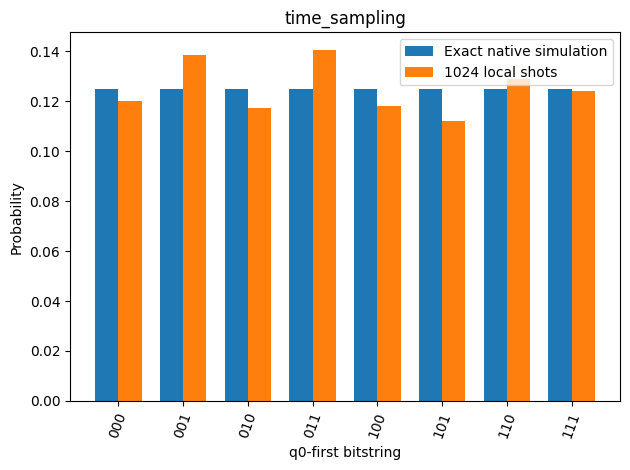

{
  "positive_correlation": {
    "correlation": 0.951171875,
    "sampling_standard_error": 0.00965039235163792
  },
  "negative_correlation": {
    "correlation": -0.966796875,
    "sampling_standard_error": 0.007989717395310368
  },
  "daily_return_mean": 9.765625000000226e-06,
  "daily_volatility": 0.014508547532663922,
  "annualized_volatility_252": 0.23031605193713103,
  "volatility_definition": "population historical volatility, ddof=0; not a forecast"
}


In [5]:
local_results = run_local(case, shots=1024, seed=20261023)
for name, result in local_results.items():
    print(name, result['execution_mode'], '| measured shots:', result['shots'])
    print('Raw measured counts:', result['counts'])
    xs = np.arange(len(result['probabilities']))
    plt.bar(xs - .18, result['ideal_probabilities'], width=.36, label='Exact native simulation')
    plt.bar(xs + .18, result['probabilities'], width=.36, label='1024 local shots')
    plt.xticks(xs, labels(case.experiments[name].num_qubits), rotation=70)
    plt.xlabel('q0-first bitstring'); plt.ylabel('Probability'); plt.title(name); plt.legend(); plt.tight_layout(); plt.show()
sampled = case.analyze(local_results)
pretty(sampled)

## 5. 最终效果与误差解释
理想参考、有限采样和离散模型误差分别呈现。命中经典最优不等于获得量子优势。

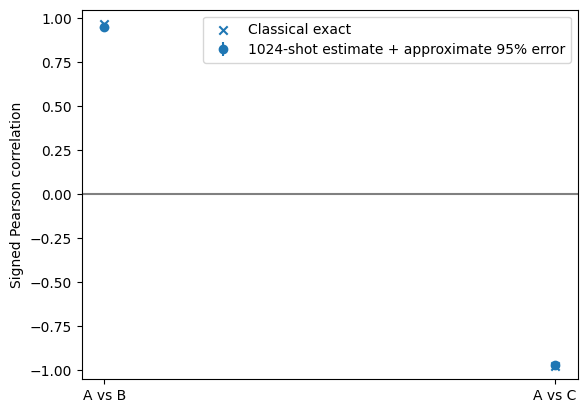

Historical annual volatility: 0.23031605193713103


In [6]:
names = ['positive_correlation', 'negative_correlation']
values = [sampled[name]['correlation'] for name in names]
error = [1.96 * sampled[name]['sampling_standard_error'] for name in names]
plt.errorbar([0, 1], values, yerr=error, fmt='o', label='1024-shot estimate + approximate 95% error')
plt.scatter([0, 1], [case.reference[name] for name in names], marker='x', label='Classical exact')
plt.xticks([0, 1], ['A vs B', 'A vs C']); plt.axhline(0, color='gray'); plt.ylim(-1.05, 1.05)
plt.ylabel('Signed Pearson correlation'); plt.legend(); plt.show()
print('Historical annual volatility:', sampled['annualized_volatility_252'])

## 5.1 统计边界与硬件验收状态

        优化案例另外区分可行率、可行条件下最优命中率、无条件最优命中率及条件平均目标值。
        风险案例使用保留离散分位点规则的多项分布 bootstrap，并用 DKW 范围检查 VaR 是否稳定。
        未观测尾部在经验 bootstrap 中仍然没有概率质量，因此这些区间不能认证未见的稀有风险。
        各状态概率给出 Bonferroni 调整的 Wilson 近似区间；TVD 仅作分布诊断。
        没有事先批准的业务容差，不能自行宣称硬件 PASS。本地结果的硬件状态始终为 NOT_EXECUTED。

In [7]:
from quantumbridge.finance.acceptance import analyze_case_evidence
sampling_acceptance = analyze_case_evidence(case, local_results)
print('Hardware acceptance:', sampling_acceptance['hardware_status'])
for name, diagnostic in sampling_acceptance['experiment_diagnostics'].items():
    print(name, '| ideal-vs-local TVD:', diagnostic['total_variation_distance'])
    if 'optimization' in diagnostic:
        pretty({key: value for key, value in diagnostic['optimization'].items() if key != 'feasible_states'})
    if 'risk_uncertainty' in diagnostic:
        pretty(diagnostic['risk_uncertainty'])

Hardware acceptance: NOT_EXECUTED
positive_correlation | ideal-vs-local TVD: 0.045005700351921585
negative_correlation | ideal-vs-local TVD: 0.028948345506214165
time_sampling | ideal-vs-local TVD: 0.033203124999999944


## 6. 同一电路接入夸父真机

        本批已获 owner 授权的上限：总计20个任务（包括位序校准），每任务1024 shots，最多6量子比特，
        遇收费提示停止。实际五类共8个业务电路，加1个非对称位序校准，共9个任务、9216 shots。
        通过 `QB_FINANCE_RUN_CLOUD=1` 显式开启；有效密钥仅通过 `QUAFU_TOKEN` 或
        `QUAFU_API_TOKEN` 进入内核环境，**不要写在代码格中**。
        Python>=3.12 的云环境需要项目已有的 `quafu-cloud` 可选依赖。

        `QB_QUAFU_BACKEND` 可指定真实设备，默认 Dongling（不保证当前在线）；
        所有五份笔记共享 `output/finance-hardware/session.json` 任务账本。
        每个 task ID 在等待结果前落盘，超时后重跑只取回该任务，不自动重复提交。
        该账本不能被多个内核同时写入。一次完整批次应顺序执行这五份笔记。
        不删除账本来重试；服务端接受与本地落盘之间仍有崩溃窗口，应先核对任务页。

        校准制备 $|10angle$，从 counts 识别 q0-first/q0-last；优势频率不足80%时停止。
        硬件结果必须包含真实任务 ID、实际 shots、原始 counts、位序与电路 SHA256。
        没有最终 counts 时不能标为硬件验收通过，也不会拿本地结果填充。
        SDK没有账单报价接口；限制任务/shot 数不等于保证免费。

Previously retrieved real hardware counts; no new submission:
{
  "case": "correlation",
  "hardware_status": "INCONCLUSIVE",
  "hardware_status_reason": "business tolerances not approved; receipt consistency is not independent hardware certification",
  "reference": {
    "positive_correlation": 0.9661739219933148,
    "negative_correlation": -0.9726661195352715,
    "daily_return_mean": 0.0006250000000000001,
    "daily_volatility": 0.01467086824288188,
    "annualized_volatility_252": 0.23289281332836362
  },
  "ideal_circuit_analysis": {
    "positive_correlation": {
      "correlation": 0.9661739219933156,
      "sampling_standard_error": 0.00806304292753518
    },
    "negative_correlation": {
      "correlation": -0.9726661195352715,
      "sampling_standard_error": 0.007260050162086259
    },
    "daily_return_mean": 0.0006250000000000001,
    "daily_volatility": 0.014670868242881876,
    "annualized_volatility_252": 0.23289281332836356,
    "volatility_definition": "population

Hardware execution COMPLETE; numerical acceptance: INCONCLUSIVE
Actual task: 2610231236118773106 | backend: Dongling | shots: 1024
Raw provider counts: {'0000': 61, '0100': 66, '1000': 73, '1010': 47, '1110': 44, '1101': 78, '0010': 42, '1011': 70, '1100': 74, '0001': 83, '0111': 43, '1001': 100, '1111': 69, '0011': 56, '0110': 44, '0101': 74}
Normalized q0-first counts: {'0000': 61, '0010': 66, '0001': 73, '0101': 47, '0111': 44, '1011': 78, '0100': 42, '1101': 70, '0011': 74, '1000': 83, '1110': 43, '1001': 100, '1111': 69, '1100': 56, '0110': 44, '1010': 74}


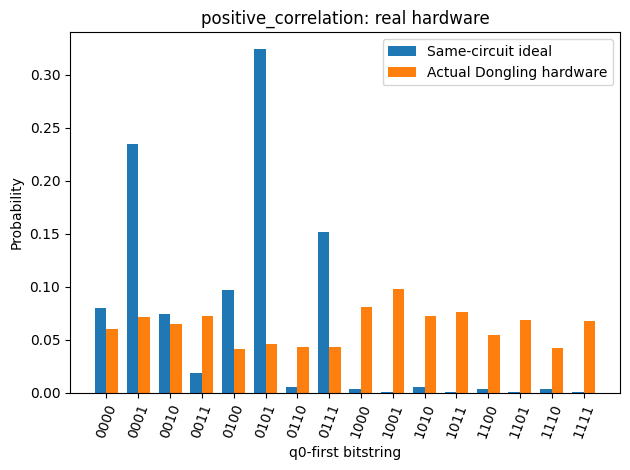

Actual task: 2610231236189351427 | backend: Dongling | shots: 1024
Raw provider counts: {'0010': 35, '0110': 37, '1000': 95, '0001': 96, '1101': 77, '1011': 60, '1100': 65, '0000': 85, '1001': 102, '1010': 53, '1110': 33, '0011': 74, '1111': 66, '0101': 52, '0100': 50, '0111': 44}
Normalized q0-first counts: {'0100': 35, '0110': 37, '0001': 95, '1000': 96, '1011': 77, '1101': 60, '0011': 65, '0000': 85, '1001': 102, '0101': 53, '0111': 33, '1100': 74, '1111': 66, '1010': 52, '0010': 50, '1110': 44}


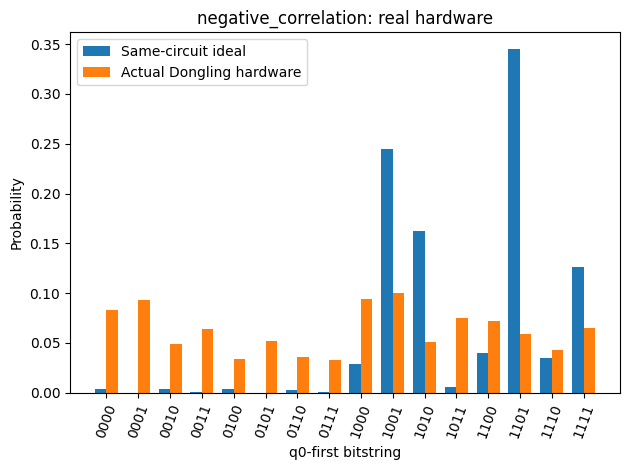

Actual task: 2610231236333069511 | backend: Dongling | shots: 1024
Raw provider counts: {'101': 75, '010': 163, '011': 185, '000': 159, '001': 147, '100': 88, '110': 86, '111': 121}
Normalized q0-first counts: {'101': 75, '010': 163, '110': 185, '000': 159, '100': 147, '001': 88, '011': 86, '111': 121}


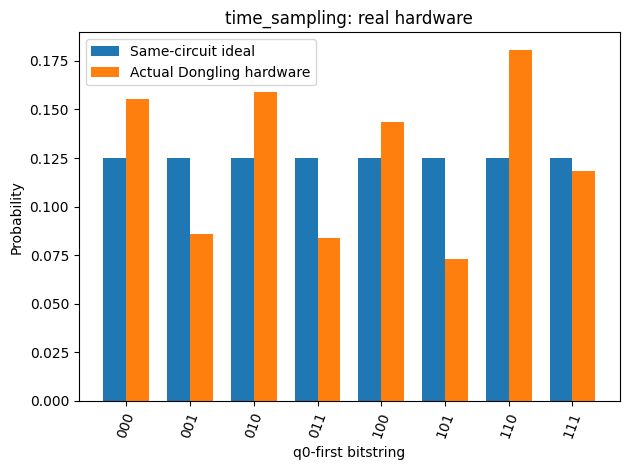

In [8]:
cloud_results = None
if os.environ.get('QB_FINANCE_RUN_CLOUD') == '1':
    session = FinanceCloudSession.from_environment(
        os.environ.get('QB_QUAFU_BACKEND', 'Dongling'),
        journal=ROOT / 'output' / 'finance-hardware' / 'session.json',
        max_tasks=20, shots=1024, max_qubits=6)
    pretty(session.preflight(list(build_finance_cases().values())))
    cloud_results = session.run(case, timeout=300, poll_interval=2)
    assert all(result['hardware_access'] for result in cloud_results.values())
    pretty({name: {k: result[k] for k in ['task_id', 'backend', 'shots', 'raw_counts', 'provider_bit_order']}
            for name, result in cloud_results.items()})
    print('REAL CLOUD FINANCIAL RESULTS:')
    pretty(case.analyze(cloud_results))
elif os.environ.get('QB_FINANCE_REPLAY_HARDWARE') == '1':
    evidence_path = ROOT / 'output' / 'jupyter-notebook' / 'finance' / (case.key + '_hardware_evidence.json')
    existing = json.loads(evidence_path.read_text(encoding='utf-8'))
    cloud_results = existing['hardware_results']
    print('Previously retrieved real hardware counts; no new submission:')
    pretty(analyze_case_evidence(case, cloud_results))
else:
    print('HARDWARE NOT EXECUTED: cloud opt-in disabled. All results above are LOCAL ONLY.')
if cloud_results is not None:
    hardware_acceptance = analyze_case_evidence(case, cloud_results)
    print('Hardware execution COMPLETE; numerical acceptance:', hardware_acceptance['hardware_status'])
    for name, result in cloud_results.items():
        print('Actual task:', result['task_id'], '| backend:', result['backend'], '| shots:', result['shots'])
        print('Raw provider counts:', result['raw_counts'])
        print('Normalized q0-first counts:', result['counts'])
        xs = np.arange(len(result['probabilities']))
        ideal = local_results[name]['ideal_probabilities']
        plt.bar(xs - .18, ideal, width=.36, label='Same-circuit ideal')
        plt.bar(xs + .18, result['probabilities'], width=.36, label='Actual ' + result['backend'] + ' hardware')
        plt.xticks(xs, labels(case.experiments[name].num_qubits), rotation=70)
        plt.xlabel('q0-first bitstring'); plt.ylabel('Probability'); plt.title(name + ': real hardware')
        plt.legend(); plt.tight_layout(); plt.show()

## 7. 本案例的交付证据

        下格保存可复查的输入、参考、中间结果、模拟 counts 和分析结果。
        `hardware_status=not_executed` 不是通过认证；只在取得真实 counts 时写入硬件证据。
        云平台执行硬件电路，本地执行数据加载、优化和金融后处理。

In [9]:
evidence = {
    'case': case.key, 'title': case.title, 'inputs': case.inputs,
    'intermediate': case.intermediate, 'reference': case.reference,
    'local_results': local_results, 'local_analysis': case.analyze(local_results),
    'hardware_status': 'completed' if cloud_results is not None else 'not_executed',
    'hardware_results': cloud_results,
    'hardware_analysis': None if cloud_results is None else case.analyze(cloud_results),
    'acceptance': analyze_case_evidence(case, cloud_results),
    'scope': 'synthetic small research case; not full industry coverage or investment advice',
}
suffix = '_hardware_evidence.json' if cloud_results is not None else '_evidence.json'
destination = ROOT / 'output' / 'jupyter-notebook' / 'finance' / (case.key + suffix)
destination.parent.mkdir(parents=True, exist_ok=True)
destination.write_text(json.dumps(evidence, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
print('Evidence:', destination.name, '| hardware:', evidence['hardware_status'])

Evidence: correlation_hardware_evidence.json | hardware: completed


## 8. 练习、边界和扩展

        练习：将本地采样从1024增加到4096 shots，保持模型和电路不变，比较误差。
        下面只运行模拟器，**不会增加云端shots或创建新任务**。
        解答思路：比较多个随机种子的误差分布，不能要求每个种子的误差都单调下降。
        采样标准误差一般随 $1/\sqrt N$ 缩小；量子硬件偏差不会由增加 shots 自动消失。

        常见陷阱：把纯 Python 预处理称为硬件能力、把本地 counts 称为真机、按最多出现的位串直接作业务决策、
        忽略负相关符号、混淆风险中性和真实概率、把1024 shots尾部结果当作精确VaR。
        后续可扩展更大模型、真实数据、读出误差缓解、硬件闭环与独立回测；这里没有宣称这些已实现。

In [10]:
more_shots = run_local(case, shots=4096, seed=20261023)
print('LOCAL 4096-shot comparison (no cloud):')
pretty(case.analyze(more_shots))

LOCAL 4096-shot comparison (no cloud):


{
  "positive_correlation": {
    "correlation": 0.9638671875,
    "sampling_standard_error": 0.0041627467234360265
  },
  "negative_correlation": {
    "correlation": -0.9775390625,
    "sampling_standard_error": 0.0032934382272828844
  },
  "daily_return_mean": -0.00010498046874999993,
  "daily_volatility": 0.014693357030302199,
  "annualized_volatility_252": 0.233249811761173,
  "volatility_definition": "population historical volatility, ddof=0; not a forecast"
}


## 9. 数学与接口参考

        本项目独立实现，未拷贝上游 SDK 源码或教程代码。
        [Qiskit Finance：组合优化](https://qiskit-community.github.io/qiskit-finance/tutorials/01_portfolio_optimization.html)、
        [欧式看涨期权](https://qiskit-community.github.io/qiskit-finance/tutorials/03_european_call_option_pricing.html)、
        [信用风险](https://qiskit-community.github.io/qiskit-finance/tutorials/09_credit_risk_analysis.html)
        提供应用定义参考；本批采用直接采样，而不是复现其 QAE 算法。
        [Quantum Risk Analysis](https://arxiv.org/abs/1806.06893)、
        [Option Pricing using Quantum Computers](https://arxiv.org/abs/1905.02666) 是算法背景，
        论文中的加速结论不适用于本批直接采样实现。
        [QuarkStudio 电路提交接口](https://quarkstudio.readthedocs.io/en/latest/usage/code/transpiler/)
        用于 `quark.Task`、QASM 和 `repeat × 1024` 传输合同。